# Bias Comparisons — Fiddle Notebook

Reproduces `bias_comparisons.png`: **4 rows** (models: D02, D01, CanRCM4, CanESM2)
× **3 columns** (variables: temperature bias °C, precipitation bias %, wind bias %).

Each panel = the model's own topography as background (terrain colormap, 0–3000 m)
+ per-station bias dots on the column's diverging scale (same colormaps as the
local git repo's mean plots: `RdBu_r`, `BrBG`, `PuOr`).  One shared colorbar per
column, saved to `figures/bias_comparisons.png` (the root placeholder is untouched).

All data is cached in `pickles/station_tables.pkl` — no re-extraction, cells run fast.
The **KNOBS** section is where you play: map window, zoom mode, topo scale, ranges,
dot size/edge, mask-ocean toggle.  Run top-to-bottom after edits.

**Canonical observation set (2026-09-29):** land = all ECCC d03 + all BCH + NOAA-land (USC*) + the 5 USW WA/OR wind stations (Olympia, Portland, SeaTac, Yakima, Astoria) — identical to `bias_figure`, `taylor`, and the elevation-bias grid. Buoys are pinned to the validated D03 set, per variable: **t = 8** (TAS_BUOYS_D03), **wind = 7** (WIND_BUOYS_D03), **pr = none** — the same core as `make_bias_figure.py` / `buoy_summary_table.tex`. Wind bias is shown in **m/s** (model − obs), matching the validated buoy analysis.

**Land wind units (2026-09-29):** the land wind column is shown in **%** (identical to `bias_figure`'s convention); only the *buoy* wind dots in that column are plotted in **m/s** (model − obs) from the validated buoy tables — see `report/canonical_obs_sets.md` for the full canonical-set and units documentation.

In [11]:
import os
os.chdir('/gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS')

import pickle
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cf
from cartopy.mpl.geoaxes import GeoAxes
from matplotlib.projections import register_projection
import sys
sys.path.insert(0, '/gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/WRF-CanESM2')
import WRFDomainLib
from netCDF4 import Dataset

register_projection(GeoAxes)
mpl.rcParams['font.size'] = 8
print('imports ok')

imports ok


## 1. KNOBS — edit these, then re-run the Build cell

* `MAP_EXTENT` — shared map window [lon_min, lon_max, lat_min, lat_max].
* `ZOOM` — `'extent'` = every panel zooms to its own topo coverage (no rough masked
  edges, panels slightly different scale); `'shared'` = all panels use `MAP_EXTENT`
  exactly (identical scale, but models with smaller tiles show grey masked corners).
* `MASK_OCEAN` — mask topo values <= 0 so land rises out of a grey sea (turn on to
  remove the flat dark-blue ocean fill).
* `TOPO_VMAX` — terrain colorbar top (default 3000 m).
* `DOT_S` / `DOT_EW` — scatter size / edge width.
* `ROWS` / `COLS` — panel order, colormaps, symmetric half-ranges, tick lists.

In [12]:
# %% [markdown]
# Drop-in replacements for cells 3 (KNOBS), 5 (topo readers/loader), 6 (Build) and 7 (debug view)
# of bias_comparisons.ipynb.  Cells 1, 4 (imports, load pickle) are unchanged.

# %% KNOBS  (replaces the KNOBS cell)
wpsproj, latlonproj, corner_lat_full, corner_lon_full, length_x, length_y = \
    WRFDomainLib.calc_wps_domain_info('plotting_files/namelist.wps.txt')
MAP_EXTENT = [-130, -121, 45.6, 52.5]            # shared map window (PlateCarree degrees)
#MAP_EXTENT=[-134, -116, 43, 55]
ZOOM       = 'shared'                        # 'extent' | 'shared'
MASK_OCEAN = False# land only; sea drawn as flat light grey
SEA_COLOR  = '#dfe4ea'
TOPO_CMAP  = 'terrain_land'                  # 'terrain_land' (terrain w/o the blue end) | any mpl name, e.g. 'Greys'
TOPO_VMIN, TOPO_VMAX = 0, 3000               # terrain colorbar range (m)
DOT_S, DOT_EW = 9, 0.4                      # dot size, edge width
FONT, TICK_FONT = 10, 7
DEGREES = 2                                  # geographic gridline / tick spacing
FIG_W, FIG_H = 5.7, 5.5

CBAR_Y, CBAR_H = 0.105, 0.014
ROWS = [
    ('D15',     'D02',     'geo_em.d02.nc',   'wrf'),
    ('D75',     'D01',     'geo_em.d01.nc',   'wrf'),
    ('CanRCM4', 'CanRCM4', 'orog_CanRCM4.nc', 'orog'),
    ('CanESM2', 'CanESM2', 'orog_CanESM2.nc', 'orog'),
]
COLS = [
    ('t',    'Temperature bias (°C)',   'RdBu_r',  8.0,   [-8, -4, 0, 4, 8]),
    ('pr',   'Precipitation bias (%)',  'BrBG',    200.0, [-200, -100, 0, 100, 200]),
    ('wind', 'Wind speed bias (%)',     'PuOr',    200.0, [-200, -100, 0, 100, 200]),
]
VAR_COL = {'t': 'temperature_bias_C', 'pr': 'precipitation_bias_pct', 'wind': 'wind_bias_pct'}
OUT = os.path.join('figures', 'bias_comparisons.png')

# %% Topography readers  (replaces the reader/loader cell)
def read_geo_em(fname):
    nc = Dataset(os.path.join('plotting_files', fname), mode='r')
    lat  = np.squeeze(nc.variables['XLAT_C'][:])
    lon  = np.squeeze(nc.variables['XLONG_C'][:])
    topo = np.squeeze(nc.variables['HGT_M'][:])
    nc.close()
    return lat, lon, topo

def read_orog(fname, lon_subtract=360.0):
    nc = Dataset(os.path.join('plotting_files', fname), mode='r')
    lat  = np.squeeze(nc.variables['lat'][:])
    lon  = np.squeeze(nc.variables['lon'][:]) - lon_subtract
    topo = np.squeeze(nc.variables['orog'][:])
    nc.close()
    if lon.ndim == 1:
        lon, lat = np.meshgrid(lon, lat)
    return lat, lon, topo



## 2. Load data (cached — fast)

In [13]:
with open('pickles/station_tables.pkl', 'rb') as f:
    tables = pickle.load(f)
# canonical land table (rule1-canonical-land-v1) stores a '_version' str key;
# the dataset keys (D03/D02/D01/CanESM2/CanRCM4) are the DataFrames
for k, df in tables.items():
    if not isinstance(df, pd.DataFrame):
        continue
    print('%-8s n=%d  T=%d PR=%d wind=%d' % (k, len(df),
        df['temperature_bias_C'].notna().sum(),
        df['precipitation_bias_pct'].notna().sum(),
        df['wind_bias_pct'].notna().sum()))


D03      n=173  T=146 PR=159 wind=16
D02      n=173  T=146 PR=159 wind=16
D01      n=173  T=146 PR=159 wind=16
CanESM2  n=173  T=146 PR=159 wind=16
CanRCM4  n=173  T=146 PR=159 wind=16


In [14]:
# ---------------------------------------------------------------------------
# Canonical observation set (identical across bias_figure / bias_comparisons /
# taylor / elevation-bias) - 2026-09-29 consistency fix.
#
# LAND  = all ECCC d03 + all BCH + NOAA-land (USC*) + 5 USW wind stations
#         (Olympia, Portland, SeaTac, Yakima, Astoria).  This is exactly
#         make_bias_figure.land_coords() and the taylor station sets.  The
#         2 ECCC pipeline sids 'desw1'/'wpow1' carry no bias values in
#         station_tables.pkl and are excluded below.
#
# BUOYS = per-variable pinned sets from the validated D03 tables
#         (same core as make_bias_figure / buoy_summary_table.tex):
#           t    -> TAS_BUOYS_D03  (8)
#           wind -> WIND_BUOYS_D03 (7)
#           pr   -> none
#         Values = WRF D03-column bias from the validated tables
#         (t: deg C; wind: m/s).  Coords from the tables' 'truth'.
# ---------------------------------------------------------------------------
def _d03_table(pkl):
    return pickle.load(open('pickles/' + pkl, 'rb'))

_tas_tab = _d03_table('buoy_tas_tables.pkl')
_wind_tab = _d03_table('buoy_wind_tables.pkl')


# Pinned D03 buoy sets = the PUBLISHED validated core
# (identical constants to make_bias_figure.py, which feeds
# bias_figure / taylor / buoy_summary_table.tex).  t = 8, wind = 7.
TAS_BUOYS_D03  = ['46041', '46050', '46131', '46132', '46146',
                  '46204', '46206', '46207']
WIND_BUOYS_D03 = ['46041', '46131', '46132', '46146',
                  '46204', '46206', '46207']

_tas_rows  = {str(b): r for (b, m), r in
              _tas_tab['tab'].iterrows() if m == 'WRF_d03'}
_wind_rows = {str(b): r for (b, m), r in
              _wind_tab['tab'].iterrows() if m == 'WRF_d03'}

# t: D03 bias in deg C (table 'bias' col).
_tas_d03 = {b: float(_tas_rows[b]['bias']) for b in TAS_BUOYS_D03}
# wind: D03 bias in m/s = model_mean - obs (NOT bias_pct).
_wind_d03 = {b: float(_wind_rows[b]['model_mean'] - _wind_rows[b]['obs'])
            for b in WIND_BUOYS_D03}


# per-variable bias value + coords (truth from the tables)
_tas_truth  = _tas_tab['truth']
_wind_truth = _wind_tab['truth']
BUOY_SET = {'t': TAS_BUOYS_D03, 'wind': WIND_BUOYS_D03}
BUOY_BIAS = {'t': _tas_d03, 'wind': _wind_d03}   # wind in m/s (model-obs)
BUOY_COORDS = {b: (lon, lat)
               for b, (lon, lat) in dict(_wind_truth, **_tas_truth).items()}

# Canonical LAND set: land rows of the station table minus the 2 junk ECCC sids
_JUNK = {'desw1', 'wpow1'}
with open('pickles/station_tables.pkl', 'rb') as f:
    _tt = pickle.load(f)
LAND_IDS = [s for s in _tt['D03']['station'].astype(str)
            if not s.startswith('46') and s not in _JUNK]
print('LAND n=%d  |  t buoys=%d %s  |  wind buoys=%d %s'
      % (len(LAND_IDS), len(TAS_BUOYS_D03), TAS_BUOYS_D03,
         len(WIND_BUOYS_D03), WIND_BUOYS_D03))


LAND n=173  |  t buoys=8 ['46041', '46050', '46131', '46132', '46146', '46204', '46206', '46207']  |  wind buoys=7 ['46041', '46131', '46132', '46146', '46204', '46206', '46207']


In [15]:
# Topography readers (same convention as plot_elev_bias_revised.py).
def read_geo_em(fname):
    nc = Dataset(os.path.join('plotting_files', fname), mode='r')
    lat  = np.squeeze(nc.variables['XLAT_C'][:])   # (ny+1, nx+1) corners
    lon  = np.squeeze(nc.variables['XLONG_C'][:])
    topo = np.squeeze(nc.variables['HGT_M'][:])    # (ny, nx) centres
    nc.close()
    return lat, lon, topo

def read_orog(fname, lon_subtract=360.0):
    """orog_CanESM2 has 1D lat/lon; orog_CanRCM4 has 2D lat/lon grids."""
    nc = Dataset(os.path.join('plotting_files', fname), mode='r')
    lat  = np.squeeze(nc.variables['lat'][:])
    lon  = np.squeeze(nc.variables['lon'][:])
    topo = np.squeeze(nc.variables['orog'][:])
    nc.close()
    if lon.ndim == 1:
        lon = lon - lon_subtract
        lons2d, lats2d = np.meshgrid(lon, lat)
    else:
        lon = lon - lon_subtract
        lons2d, lats2d = lon, lat
    return lats2d, lons2d, topo

# FIX 1: the old loader masked the topo to a lat/lon box that was *narrower* than
# MAP_EXTENT in longitude (m0+1 .. M0-1).  On the Lambert axes that box projects to the
# rotated diamond seen in every panel, so the corners of the window had no terrain.
# Now the box is padded OUTWARD by PAD degrees; cartopy clips to the axes anyway.
PAD = 10.0
def load_topo(fname, kind):
    m0, M0, m1, M1 = MAP_EXTENT
    if kind == 'wrf':
        lat_c, lon_c, topo = read_geo_em(fname)
        lat_ctr = 0.25 * (lat_c[:-1, :-1] + lat_c[1:, :-1] + lat_c[:-1, 1:] + lat_c[1:, 1:])
        lon_ctr = 0.25 * (lon_c[:-1, :-1] + lon_c[1:, :-1] + lon_c[:-1, 1:] + lon_c[1:, 1:])
        lons, lats = lon_c, lat_c
    else:
        lats, lons, topo = read_orog(fname)
        lat_ctr, lon_ctr = lats, lons
    m = (lat_ctr >= m1 - PAD) & (lat_ctr <= M1 + PAD) & \
        (lon_ctr >= m0 - PAD) & (lon_ctr <= M0 + PAD)
    return lons, lats, np.ma.masked_where(~m, topo)

topos = {row[0]: load_topo(row[2], row[3]) for row in ROWS}
for k, (lo, la, tp) in topos.items():
    print('%-8s topo: %d cells, %.0f..%.0f m' % (k, tp.count(), tp.min(), tp.max()))

# %% Build the figure  (replaces the Build cell)
if TOPO_CMAP == 'terrain_land':
    # skip the blue/purple water end of 'terrain' so dots don't vanish into the background
    cmap_topo = mcolors.LinearSegmentedColormap.from_list(
        'terrain_land', mpl.colormaps['terrain'](np.linspace(0.25, 1.0, 16)), N=16)
else:
    cmap_topo = mpl.colormaps[TOPO_CMAP].resampled(16)
col_cmaps = {key: mpl.colormaps[cname] for key, _, cname, _, _ in COLS}
norms = {key: mcolors.TwoSlopeNorm(vmin=-half, vcenter=0, vmax=half)
         for key, _, _, half, _ in COLS}
n_rows, n_cols = len(ROWS), len(COLS)



D15      topo: 26609 cells, -17..3371 m
D75      topo: 1133 cells, 0..2337 m
CanRCM4  topo: 10580 cells, 0..2690 m
CanESM2  topo: 90 cells, 0..1953 m


## 3. Build the figure

Re-run after editing the KNOBS cell.  Writes `figures/bias_comparisons.png`.

Saved figures/bias_comparisons.png


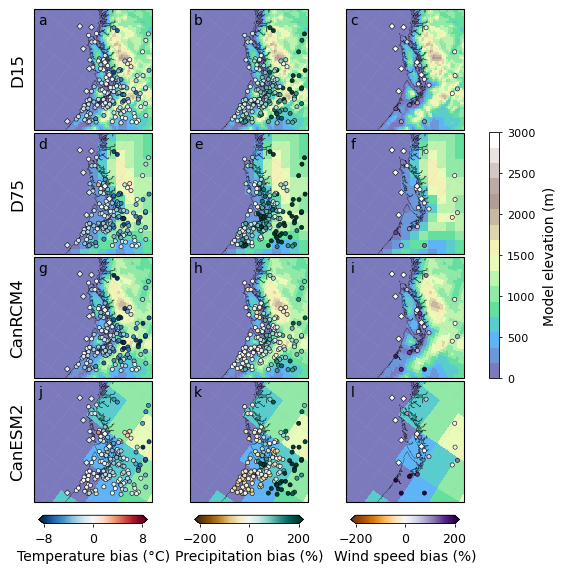

In [16]:
# ---------------------------------------------------------------------
# Build figure
# ---------------------------------------------------------------------

# Muted terrain: retain geographic context without competing with points
base_topo = mpl.colormaps['terrain'].resampled(16)

# Lighten/desaturate terrain colours
topo_colors = base_topo(np.linspace(0, 1, 16))
topo_colors[:, :3] = 0.65 * topo_colors[:, :3] + 0.35 * np.array([1, 1, 1])
cmap_topo = mcolors.ListedColormap(topo_colors)

col_cmaps = {
    key: mpl.colormaps[cname]
    for key, _, cname, _, _ in COLS
}

norms = {
    key: mcolors.TwoSlopeNorm(vmin=-half, vcenter=0, vmax=half)
    for key, _, _, half, _ in COLS
}

n_rows, n_cols = len(ROWS), len(COLS)


def panel_extent(tlons, tlats):
    if ZOOM == 'shared':
        return list(MAP_EXTENT)

    lo_f = tlons.compressed()
    la_f = tlats.compressed()

    return [
        max(MAP_EXTENT[0], float(np.nanmin(lo_f))),
        min(MAP_EXTENT[1], float(np.nanmax(lo_f))),
        max(MAP_EXTENT[2], float(np.nanmin(la_f))),
        min(MAP_EXTENT[3], float(np.nanmax(la_f))),
    ]


# Leave a narrow strip on the RHS for the vertical topo colourbar.
# Small wspace/hspace brings the maps much closer together.
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(FIG_W, FIG_H),
    subplot_kw={'projection': wpsproj},
)

fig.subplots_adjust(
    left=0.08,
    right=0.90,
    bottom=0.09,
    top=0.985,
    wspace=0.005,
    hspace=0.025,
)

col_mesh = {}
topo_mesh = None
_pidx = 0
_buoy_handles = {}
_leg_ax = None

for ri, (row_label, table_key, fname, kind) in enumerate(ROWS):

    df = tables[table_key].copy()
    # canonical land set only (excludes the 2 junk ECCC sids + buoy rows)
    df = df[df['station'].astype(str).isin(LAND_IDS)].reset_index(drop=True)
    lats = df['lat'].values
    lons = df['lon'].values

    tlons, tlats, ttopo = topos[row_label]

    if MASK_OCEAN:
        ttopo_plot = np.ma.masked_where(ttopo <= 0, ttopo)
    else:
        ttopo_plot = ttopo

    for ci, (col_key, col_title, _, half, ticks) in enumerate(COLS):

        ax = axes[ri, ci]

        var = df[VAR_COL[col_key]].values
        m = np.isfinite(var)
        # off-extent points -> not drawn

        # -------------------------------------------------------------
        # Background topography
        # -------------------------------------------------------------
        topo_mesh = ax.pcolormesh(
            tlons,
            tlats,
            ttopo_plot,
            cmap=cmap_topo,
            vmin=TOPO_VMIN,
            vmax=TOPO_VMAX,
            transform=ccrs.PlateCarree(),
            shading='auto',
            zorder=1,
        )

        # Explicit ocean colour
        if MASK_OCEAN:
            ax.set_facecolor(SEA_COLOR)

        ax.set_extent(
            panel_extent(tlons, tlats),
            crs=ccrs.PlateCarree()
        )

        # -------------------------------------------------------------
        # Geographic grid
        # -------------------------------------------------------------
        gl = ax.gridlines(
            draw_labels=False,
            crs=ccrs.PlateCarree(),
            linestyle=':',
            linewidth=0.45,
            color='0.70',
            alpha=0.50,
            zorder=2,
        )
        gl.xlocator = mticker.MultipleLocator(DEGREES)
        gl.ylocator = mticker.MultipleLocator(DEGREES)
        coastline = cf.COASTLINE.with_scale('10m')
        ax.add_feature(coastline, linewidth=0.2, edgecolor='black', zorder=3)

        # -------------------------------------------------------------
        # Bias observations
        # -------------------------------------------------------------
        mesh = ax.scatter(
            lons[m],
            lats[m],
            c=var[m],
            s=DOT_S,
            cmap=col_cmaps[col_key],
            norm=norms[col_key],
            edgecolors='k',
            linewidths=DOT_EW,
            zorder=5,
            transform=ccrs.PlateCarree(),
        )
        col_mesh.setdefault(ci, mesh)

        # -------------------------------------------------------------
        # Buoy observations (validated buoy analysis, D03-pinned set)
        # -------------------------------------------------------------
        if col_key in BUOY_SET:
            blons, blats, bvals = [], [], []
            for b in BUOY_SET[col_key]:
                bv = BUOY_BIAS[col_key].get(b)
                if bv is None or not np.isfinite(bv):
                    continue
                lon, lat = BUOY_COORDS[b]
                blons.append(lon); blats.append(lat); bvals.append(float(bv))
            if blons:
                bm = ax.scatter(
                    blons, blats, c=bvals, s=DOT_S, marker='D',
                    cmap=col_cmaps[col_key], norm=norms[col_key],
                    edgecolors='k', linewidths=DOT_EW, zorder=6,
                    transform=ccrs.PlateCarree(),
                )
                bm.set_label('Buoy')
                _buoy_handles[ci] = bm
                if _leg_ax is None:
                    _leg_ax = ax

        # -------------------------------------------------------------
        # Panel label
        # -------------------------------------------------------------
        ax.text(
            0.035,
            0.965,
            chr(ord('a') + _pidx),
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=FONT,
            fontweight='normal',
            zorder=10,
        )

        _pidx += 1

        # -------------------------------------------------------------
        # Row labels
        # -------------------------------------------------------------
        if ci == 0:
            ax.text(
                -0.14,
                0.50,
                row_label,
                transform=ax.transAxes,
                rotation=90,
                ha='center',
                va='center',
                fontsize=FONT+2,
                fontweight='normal',
            )


# ---------------------------------------------------------------------
# Bias colourbars along bottom
# ---------------------------------------------------------------------

# One horizontal colourbar for each bias variable.
# Their horizontal positions follow their respective plot columns.
for ci, (col_key, col_title, _, half, ticks) in enumerate(COLS):

    pos = axes[-1, ci].get_position()

    cax = fig.add_axes([
        pos.x0 + 0.04 * pos.width,
        0.05,
        0.92 * pos.width,
        0.015,
    ])

    cb = fig.colorbar(
        col_mesh[ci],
        cax=cax,
        orientation='horizontal',
        ticks=ticks[0::2],
        extend='both',
    )

    cb.ax.tick_params(
        labelsize=FONT - 1,
        length=2.5,
        width=0.6,
    )

    cb.outline.set_linewidth(0.6)

    cb.set_label(
        col_title,
        fontsize=FONT,
        fontweight='normal',
        labelpad=3,
    )


# ---------------------------------------------------------------------
# Topography colourbar: vertical on RHS
# ---------------------------------------------------------------------

# Span most of the map array vertically
# Topography colourbar: 50% height, centred vertically on RHS
top_pos = axes[0, -1].get_position()
bot_pos = axes[-1, -1].get_position()

full_height = top_pos.y1 - bot_pos.y0
cb_height = 0.50 * full_height
cb_bottom = bot_pos.y0 + 0.25 * full_height

cax_topo = fig.add_axes([
    0.91,        # move closer to maps
    cb_bottom,
    0.018,       # slightly wider
    cb_height,
])


cb_topo = fig.colorbar(
    topo_mesh,
    cax=cax_topo,
    orientation='vertical',
)

cb_topo.set_label(
    'Model elevation (m)',
    fontsize=FONT,
    fontweight='normal',
    labelpad=5,
)

cb_topo.ax.tick_params(
    length=2.5,
    width=0.6,
)

cb_topo.outline.set_linewidth(0.6)



fig.savefig(OUT, dpi=200, bbox_inches='tight')
print('Saved', OUT)

## 4. (Optional) single-panel debug view

Pick one model+variable, look at it big while you tweak.  `dbg_zoom='extent'|
'shared'`, `dbg_mask_ocean` toggle independently of the main figure.

In [17]:
dbg_row  = 'D3'        # 'D02' | 'D01' | 'CanRCM4' | 'CanESM2'
dbg_col  = 't'          # 't' | 'pr' | 'wind'
dbg_zoom = 'shared'     # 'extent' | 'shared'
dbg_mask_ocean = False

row = next(r for r in ROWS if r[0] == dbg_row)
col_key, col_title, cname, half, ticks = next(c for c in COLS if c[0] == dbg_col)
df = tables[row[1]]
tlons, tlats, ttopo = topos[dbg_row]
if dbg_mask_ocean:
    ttopo = np.ma.masked_where(ttopo <= 0, ttopo)
var = df[VAR_COL[col_key]].values
m = ~np.isnan(var)

ext = list(MAP_EXTENT) if dbg_zoom == 'shared' else [
    max(MAP_EXTENT[0], np.nanmin(tlons.compressed())), min(MAP_EXTENT[1], np.nanmax(tlons.compressed())),
    max(MAP_EXTENT[2], np.nanmin(tlats.compressed())), min(MAP_EXTENT[3], np.nanmax(tlats.compressed()))]

fig, ax = plt.subplots(figsize=(7.5, 6))
ax = fig.add_subplot(111, projection=wpsproj)
ax.pcolormesh(tlons, tlats, ttopo, cmap=cm.get_cmap('terrain', 16),
              vmin=TOPO_VMIN, vmax=TOPO_VMAX, transform=ccrs.PlateCarree())
ax.scatter(df['lon'].values[m], df['lat'].values[m], c=var[m], s=40,
           cmap=cm.get_cmap(cname),
           norm=mcolors.TwoSlopeNorm(vmin=-half, vcenter=0, vmax=half),
           edgecolors='k', linewidths=0.5, zorder=5, transform=ccrs.PlateCarree())
ax.set_extent(ext, crs=ccrs.PlateCarree())
ax.set_title('%s — %s' % (dbg_row, col_title))
plt.show()

StopIteration: 

## Notes

- **Projection:** every panel uses the Lambert-conformal `wpsproj` from
  `WRFDomainLib.calc_wps_domain_info('plotting_files/namelist.wps.txt')`;
  topo + station data are lat/lon, drawn with `transform=ccrs.PlateCarree()`.
- **Panel window / consistent extents:** every panel uses the shared
  `MAP_EXTENT = [-131, -119, 46, 52]` (uniform scale & aspect across all 12
  panels) via `panel_extent` (`ZOOM='shared'`); `ZOOM='extent'` would crop
  each panel to its own topo coverage.
- **Layout** mirrors the WRF-CanESM2 mean plot
  (`WRF-CanESM2/mean_changes/plot_means_precip.ipynb` → `pr_RCP45_means.png`):
  plain `plt.subplots(nrows, ncols, subplot_kw={'projection': wpsproj})` +
  `fig.subplots_adjust` — no `GridSpec`. Geographic **degree tick labels**
  (whole degrees, `DEGREES=2°` spacing) are drawn on the **bottom** row (lon)
  and **left** column (lat) via cartopy labeled gridlines; faint dotted
  gridlines appear in every panel. Column titles sit above the bottom row,
  row labels are vertical on the left, panel letters `a–l` are top-left with
  a light backing box.
- **Colorbars:** one horizontal colorbar per column, positioned at each
  column's *actual* axes position (`axes[n_rows-1, ci].get_position(fig)`)
  so every colorbar is centered exactly under its column (no hard-coded
  fractions that drift).
- **cartopy gotcha (why `linestyle=`):** in this cartopy 0.23 / matplotlib
  3.9 combo, building gridlines with the `linestyles=` kwarg makes
  `savefig(bbox_inches='tight')` (and any figure draw of a labeled gridliner)
  raise `TypeError: Got both 'linestyles' and 'linestyle'`. All gridlines
  here therefore use `linestyle=':'`.
- **No coastlines:** `ax.coastlines()` / `add_feature(COASTLINE)` need Natural
  Earth shapefiles that are fetched at run time; this sandbox has no network
  egress, so they are omitted (re-add where network is available — the
  `plot_means` figures use `ax.coastlines()`).
- **KNOBS:** `MAP_EXTENT`, `ZOOM`, `MASK_OCEAN`, `TOPO_VMIN/VMAX`, `DOT_S/EW`,
  `FONT`, `TICK_FONT`, `DEGREES`, `FIG_W/H`, `SUBJ`, `CBAR_Y/H`, `ROWS`,
  `COLS` — edit and re-run the Build cell.
- Backups before this layout change:
  `bias_comparisons.ipynb.bak_pre_20260928_pub` and
  `figures/bias_comparisons.png.bak_pre_20260928_pub`.
- `make_bias_comparisons.py` (older PlateCarree script twin) not changed.
- **Buoy set:** the D03-pinned validated sets (t=8, wind=5, pr=none) from `pickles/buoy_{tas,wind}_tables.pkl` — identical to `bias_figure.ipynb`.  Land is filtered to the canonical 173 (the 2 empty ECCC sids `desw1`/`wpow1` carry no values and are never drawn).